# Cheetah model calibration
Learn a quadrupole's transverse offset from a nine-point screen-image scan using an independent clone of an in-process LUMEcheetah virtual accelerator.

In [1]:
from copy import deepcopy
from pathlib import Path
import sys

import os

os.environ["CUDA_VISIBLE_DEVICES"] = ""

import matplotlib.pyplot as plt
import torch
from lightning.pytorch import Trainer
from cheetah.accelerator import Drift, Quadrupole, Screen, Segment
from cheetah.particles import ParticleBeam
from lume_cheetah.actions import CheetahReadOnlyNDVariable, CheetahWritableScalarVariable
from lume_cheetah.model import LUMECheetahModel
from lume_cheetah.simulator import CheetahSimulator

repository_root = next(
    directory for directory in (Path.cwd(), *Path.cwd().parents)
    if (directory / 'lume_applications' / 'model_calibration').is_dir()
)
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))

from lume_applications.model_calibration import CalibrationModule, get_trainable_parameters

torch.set_num_threads(1)

/home/rroussel/miniforge3/envs/lume/lib/python3.13/site-packages/h5py/__init__.py:36: UserWarning: h5py is running against HDF5 2.2.0 when it was built against 2.1.0, this may cause problems
  _warn(("h5py is running against HDF5 {0} when it was built against {1}, "


## Prepare example data
Build Q1, a drift, and an active screen. Fix the particle seed and screen geometry, then generate detached target images with offsets of +2 mm horizontally and -3 mm vertically. The scan and beam settings match the test fixtures, which remain independent of this notebook.

In [2]:
segment = Segment([
    Quadrupole(name='Q1', length=torch.tensor(0.5), k1=torch.tensor(1.0)),
    Drift(name='D1', length=torch.tensor(1.0)),
    Screen(
        name='SCR1', resolution=(64, 64),
        pixel_size=torch.tensor([2e-4, 2e-4]),
        method='cloud-in-cell', is_active=True,
    ),
])
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(0)
    particle_beam = ParticleBeam.from_twiss(
        beta_x=torch.tensor(1.0), beta_y=torch.tensor(1.0),
        emittance_x=torch.tensor(1e-7), emittance_y=torch.tensor(1e-7),
        num_particles=1000, energy=torch.tensor(100e6),
        total_charge=torch.tensor(1e-12),
    )
simulator = CheetahSimulator(
    segment=segment, initial_beam_distribution=particle_beam,
)
variables = [
    CheetahWritableScalarVariable(
        name='Q1_k', element_name='Q1', element_attribute='k1',
    ),
    CheetahReadOnlyNDVariable(
        name='screen_image', element_name='SCR1',
        element_attribute='reading', shape=(64, 64),
    ),
]

# Create the reference model with the defined simulator and variables
reference_model = LUMECheetahModel(simulator, action_variables=variables)
true_offset = torch.tensor([2e-3, -3e-3])
reference_model.simulator.segment.Q1.misalignment = true_offset.clone()

# create dataset by scanning quadrupole strengths and recording screen images
strengths = torch.linspace(-2.0, 2.0, 9)
images = []
for strength in strengths:
    reference_model.set({'Q1_k': strength})
    images.append(reference_model.get(['screen_image'])['screen_image'].detach().clone())
dataset = {
    'quadrupole_k1': strengths,
    'quadrupole_offset_m': true_offset.clone(),
    'pixel_size_m': reference_model.simulator.segment.SCR1.pixel_size.clone(),
    'images': torch.stack(images),
}

## Run the Lightning calibration workflow
Clone the reference model before registering the learnable offset. Fit only this two-component `torch.nn.Parameter`, starting from zero. Do not call `reset()` while fitting: it replaces the segment and discards the parameter objects held by the optimizer.

`CalibrationModule` supplies one full-scan batch per epoch and configures the provided optimizer. Lightning's `Trainer` handles gradient clearing, backpropagation, and optimizer updates. Here `max_steps=300` with the default gradient accumulation gives 300 full-batch Adam updates. `train_loss` is available to Lightning loggers and callbacks; logging and checkpoint files are disabled for this example.

The loss is full-image MSE, with predictions and targets divided by the same fixed target-image maximum. This constant rescaling improves numerical conditioning without discarding relative intensities or changing the MSE minimizer. `calibration.loss_history` records the loss before each update and one fresh evaluation after training. Ground-truth offsets are used only for the final comparison. Re-running the following cell starts a fresh fit.

In [3]:
# Create a fitting model by copying the reference model
fitting_model = deepcopy(reference_model)

# Define the offset parameter for the fitting model
offset = torch.nn.Parameter(
    torch.zeros_like(fitting_model.simulator.segment.Q1.misalignment)
)
fitting_model.simulator.segment.Q1.misalignment = offset

# Set up the optimizer and image loss scale
optimizer = torch.optim.Adam(get_trainable_parameters(fitting_model), lr=1e-4)
image_scale = dataset['images'].abs().max()
if not torch.isfinite(image_scale) or image_scale <= 0:
    raise ValueError('Target image scale must be finite and positive')

def image_loss(prediction, target):
    return torch.nn.functional.mse_loss(prediction / image_scale, target / image_scale)

calibration = CalibrationModule(
    fitting_model,
    {'Q1_k': dataset['quadrupole_k1']},
    {'screen_image': dataset['images']},
    optimizer, loss_fn=image_loss,
)
trainer = Trainer(
    accelerator='cpu', devices=1, max_steps=300, max_epochs=-1,
    logger=False, enable_checkpointing=False, enable_progress_bar=False,
    enable_model_summary=False,
)
trainer.fit(calibration)
history = calibration.loss_history

assert history[-1] < 0.1 * history[0]
torch.testing.assert_close(
    offset.detach(), dataset['quadrupole_offset_m'], atol=1e-4, rtol=0,
)
torch.testing.assert_close(reference_model.simulator.segment.Q1.misalignment, true_offset)

print(f'True offset [mm]:   {(true_offset * 1e3).tolist()}')
print(f'Fitted offset [mm]: {(offset.detach() * 1e3).tolist()}')
print(f'Loss: {history[0]:.6g} -> {history[-1]:.6g}')
print(f'Loss reduction: {100 * (1 - history[-1] / history[0]):.3f}%')

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/home/rroussel/miniforge3/envs/lume/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/rroussel/miniforge3/envs/lume/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.
/home/rroussel/miniforge3/envs/lume/lib/python3.13/site-packages/torch/autograd/graph.py:882: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12060). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA

True offset [mm]:   [2.0, -3.0]
Fitted offset [mm]: [2.0, -2.999999761581421]
Loss: 0.00634884 -> 2.43401e-15
Loss reduction: 100.000%


## Inspect and visualize results
Show the loss curve and a comparison between training images and predicted images. 

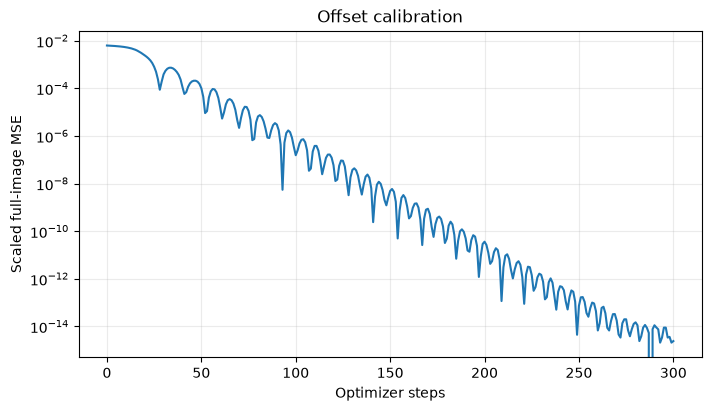

In [4]:
loss_figure, loss_axis = plt.subplots(figsize=(7, 4), layout='constrained')
loss_axis.semilogy(range(len(history)), history)
loss_axis.set(xlabel='Optimizer steps', ylabel='Scaled full-image MSE', title='Offset calibration')
loss_axis.grid(alpha=0.25)
plt.show()

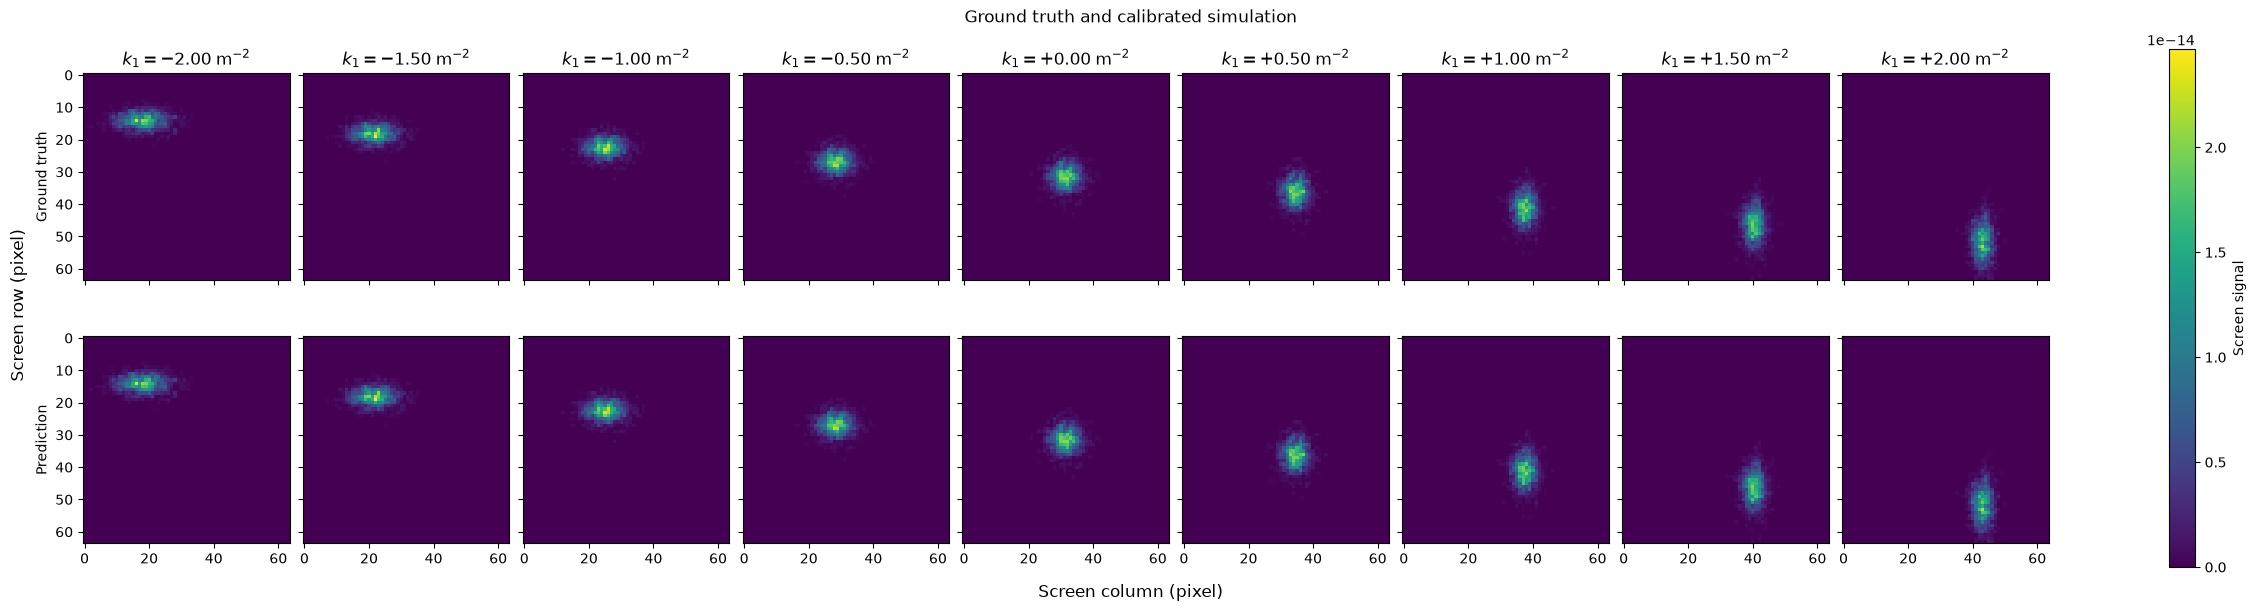

In [5]:
predicted_images = []
with torch.no_grad():
    for strength in dataset['quadrupole_k1']:
        fitting_model.set({'Q1_k': strength})
        predicted_images.append(
            fitting_model.get(['screen_image'])['screen_image'].detach().clone()
        )
predicted_images = torch.stack(predicted_images)

target_images = dataset['images'].detach().cpu().numpy()
fitted_images = predicted_images.cpu().numpy()
scan_strengths = dataset['quadrupole_k1'].detach().cpu().numpy()
shared_max = max(target_images.max(), fitted_images.max())
comparison_figure, comparison_axes = plt.subplots(
    2, len(scan_strengths), figsize=(2.5 * len(scan_strengths), 6),
    layout='constrained', squeeze=False, sharex=True, sharey=True,
)
for scan_index, strength in enumerate(scan_strengths):
    for row_index, image in enumerate([
        target_images[scan_index],
        fitted_images[scan_index],
    ]):
        axis = comparison_axes[row_index, scan_index]
        comparison_artist = axis.imshow(
            image, cmap='viridis', vmin=0, vmax=shared_max, interpolation='nearest',
        )
    comparison_axes[0, scan_index].set_title(
        rf'$k_1 = {strength:+.2f}\;\mathrm{{m}}^{{-2}}$'
    )
comparison_axes[0, 0].set_ylabel('Ground truth')
comparison_axes[1, 0].set_ylabel('Prediction')
comparison_figure.suptitle('Ground truth and calibrated simulation')
comparison_figure.supxlabel('Screen column (pixel)')
comparison_figure.supylabel('Screen row (pixel)')
comparison_figure.colorbar(
    comparison_artist, ax=list(comparison_axes.flat), label='Screen signal',
)
plt.show()

## Bayesian misalignment inference with Pyro SVI
This separate example needs only the imports and reference scan above, not the Lightning fit. Install `pyro-ppl>=1.9,<2` in the `lume` environment. The reference simulation and detached dataset remain unchanged.

`BayesianModel` maps exposed Pyro attributes to tensor attributes in an independent LUME model clone. Its default `PyroParam` attributes are point estimates. Replace the misalignment with `PyroSample(prior)` to infer a distribution instead. The adapter avoids converting LUME/Cheetah's abstract classes to PyroModule. One misalignment sample is shared by all nine images in each likelihood evaluation.

We use an independent zero-centered Normal prior with 3 mm standard deviation for each offset. The likelihood assumes independent Gaussian pixel noise with standard deviation 5% of the dataset's peak signal, in the original image units. This is an illustrative assumption for this noiseless synthetic dataset, not an estimated instrument noise model. Changing it changes posterior uncertainty; correlated pixels or model discrepancy would require a richer likelihood.

`infer_model_svi` fits an `AutoNormal` mean-field posterior with Pyro SVI, using independent guide initialization and an isolated parameter store. Location and log-scale parameters use different learning rates because the offsets are in meters. Posterior intervals below describe this variational approximation and can underestimate uncertainty. Ground-truth offsets are used only for comparison.

In [6]:
import pyro
import pyro.distributions as dist
from pyro.nn import PyroSample
from lume_applications.model_calibration.svi import BayesianModel, infer_model_svi

bayesian_model = BayesianModel(
    deepcopy(reference_model),
    {'misalignment': 'simulator.segment.Q1.misalignment'},
)
bayesian_model.misalignment = PyroSample(
    dist.Normal(torch.zeros(2), torch.full((2,), 3e-3)).to_event(1)
)
observation_noise = 0.05 * dataset['images'].max()

def svi_optimizer_settings(module_name, parameter_name):
    learning_rate = 5e-5 if '.locs.' in parameter_name else 0.03
    return {'lr': learning_rate}

with torch.random.fork_rng(devices=[]):
    torch.manual_seed(0)
    svi_result = infer_model_svi(
        bayesian_model,
        {'Q1_k': dataset['quadrupole_k1']},
        {'screen_image': dataset['images']},
        {'screen_image': observation_noise},
        steps=600, num_samples=2000, init_scale=2e-4,
        optimizer=pyro.optim.Adam(svi_optimizer_settings),
    )

offset_samples_mm = svi_result.posterior_samples['model.misalignment'].cpu() * 1e3
posterior_mean_mm = offset_samples_mm.mean(dim=0)
credible_interval_mm = torch.quantile(
    offset_samples_mm, torch.tensor([0.025, 0.975]), dim=0,
)
print(f'Posterior mean [mm]: {posterior_mean_mm.tolist()}')
print(f'95% interval bounds [mm]: {credible_interval_mm.tolist()}')
print(f'Ground truth [mm]: {(dataset["quadrupole_offset_m"] * 1e3).tolist()}')

Posterior mean [mm]: [1.9916106462478638, -3.002340078353882]
95% interval bounds [mm]: [[1.972288727760315, -3.0325047969818115], [2.0112674236297607, -2.9723899364471436]]
Ground truth [mm]: [2.0, -3.0]


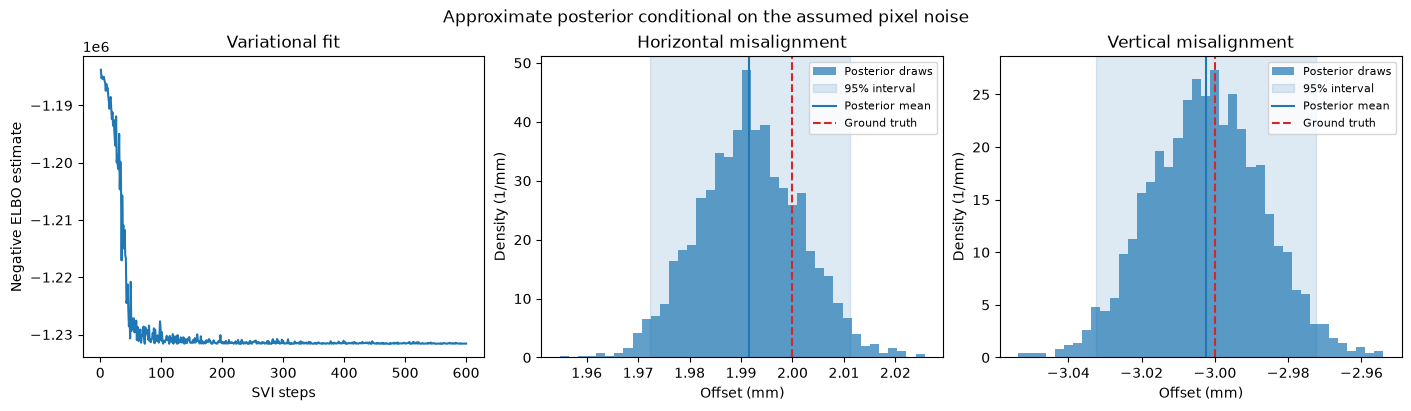

In [7]:
svi_figure, svi_axes = plt.subplots(1, 3, figsize=(14, 4), layout='constrained')
svi_axes[0].plot(range(1, len(svi_result.losses) + 1), svi_result.losses)
svi_axes[0].set(
    xlabel='SVI steps', ylabel='Negative ELBO estimate', title='Variational fit',
)
true_offset_mm = dataset['quadrupole_offset_m'].detach().cpu() * 1e3
for coordinate, axis in enumerate(svi_axes[1:]):
    samples = offset_samples_mm[:, coordinate].numpy()
    lower, upper = credible_interval_mm[:, coordinate].tolist()
    axis.hist(samples, bins=40, density=True, alpha=0.7, label='Posterior draws')
    axis.axvspan(lower, upper, color='tab:blue', alpha=0.15, label='95% interval')
    axis.axvline(
        posterior_mean_mm[coordinate].item(), color='tab:blue', label='Posterior mean',
    )
    axis.axvline(
        true_offset_mm[coordinate].item(), color='tab:red', linestyle='--',
        label='Ground truth',
    )
    axis.set(
        xlabel='Offset (mm)', ylabel='Density (1/mm)',
        title=f'{["Horizontal", "Vertical"][coordinate]} misalignment',
    )
    axis.legend(fontsize=8)
svi_figure.suptitle('Approximate posterior conditional on the assumed pixel noise')
plt.show()

## Predict screen images from the SVI posterior
Replay the fitted latent draws with `predict_model_svi`. It returns image tensors shaped `(posterior draws, scan points, height, width)` and also accepts new scan inputs without target images. Here we use the first 128 draws and the training quadrupole strengths for comparison.

The top row shows training images; the middle row shows the average simulated image across posterior draws, not the image at the average misalignment. These rows share an intensity scale. The bottom row shows pixelwise posterior standard deviation (`svi_image_std`) with its own shared color scale. This uncertainty comes from the inferred misalignment; it does not include additional observation noise.

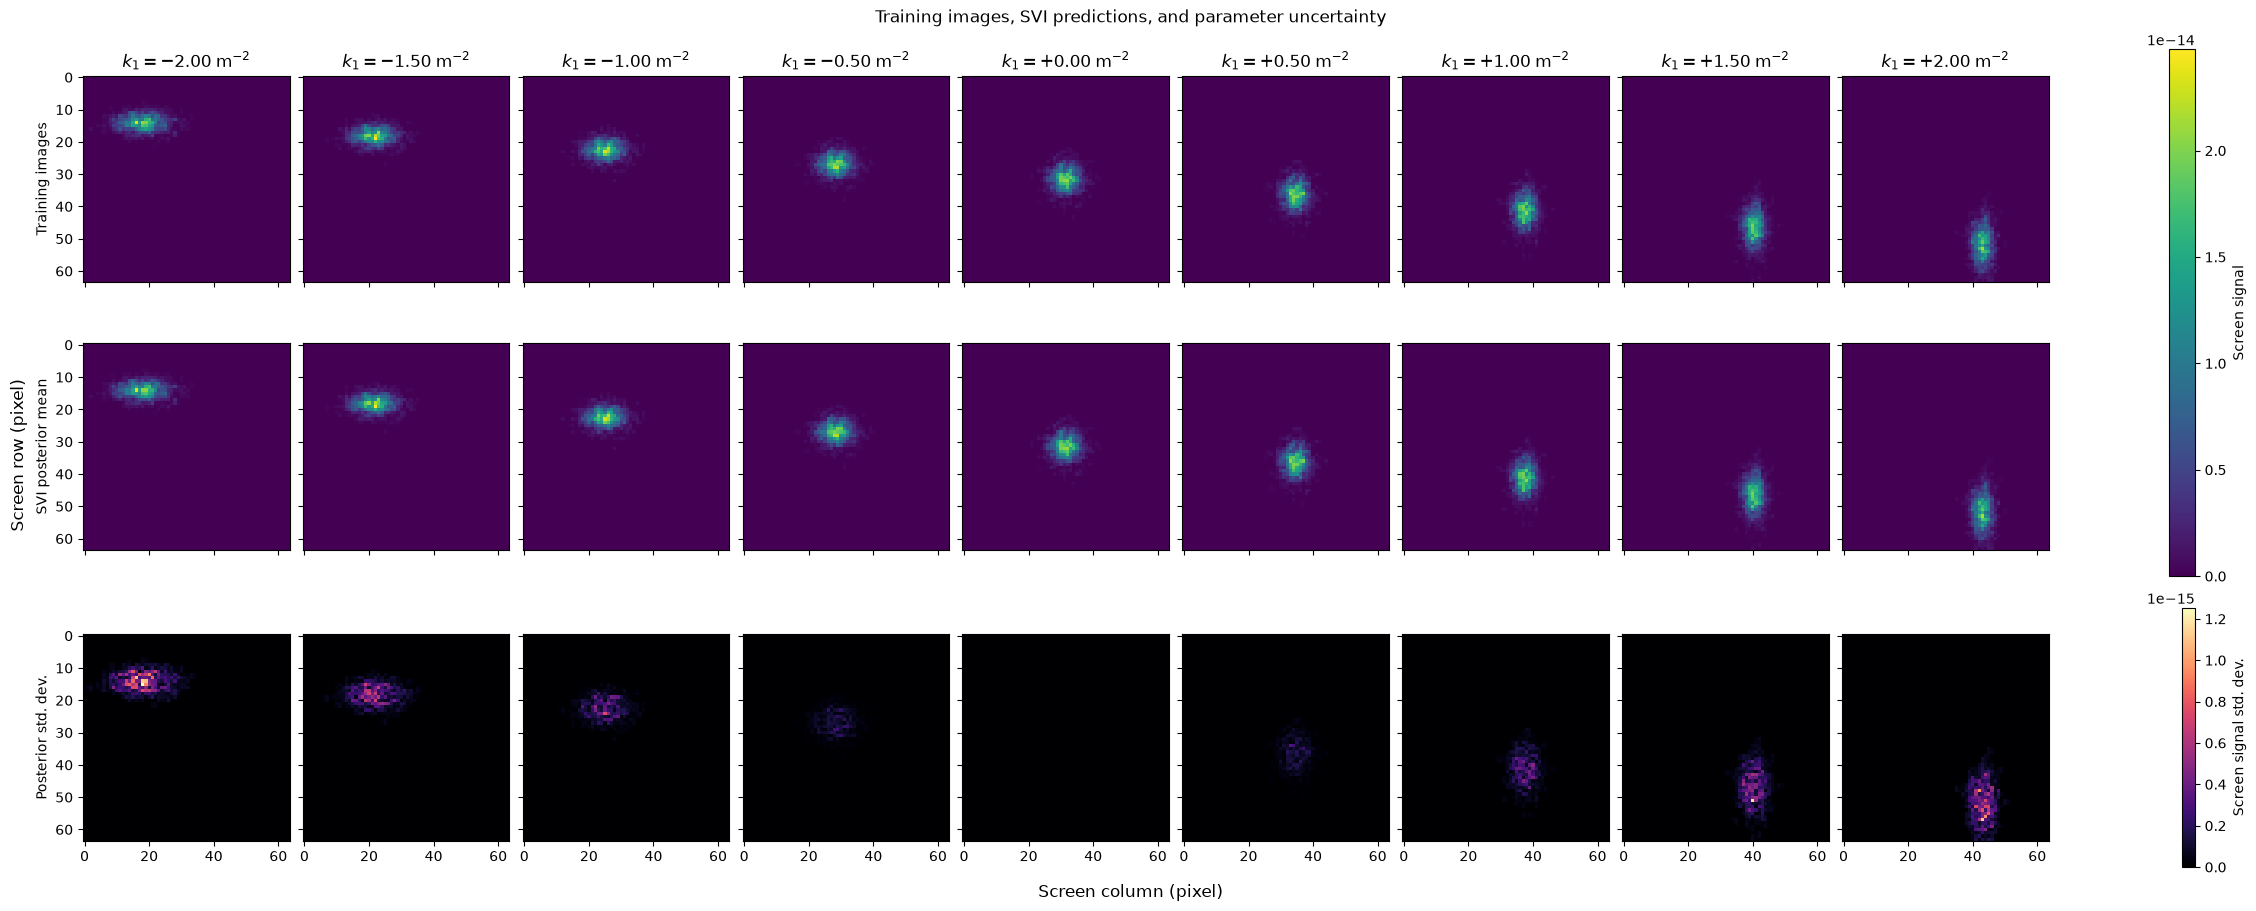

In [9]:
from lume_applications.model_calibration.svi import predict_model_svi

svi_image_draws = predict_model_svi(
    bayesian_model,
    {'Q1_k': dataset['quadrupole_k1']},
    ['screen_image'],
    svi_result.posterior_samples,
    num_samples=128,
)['screen_image']
svi_image_mean = svi_image_draws.mean(dim=0)
svi_image_std = svi_image_draws.std(dim=0)

training_images = dataset['images'].detach().cpu().numpy()
posterior_mean_images = svi_image_mean.cpu().numpy()
uncertainty_images = svi_image_std.cpu().numpy()
svi_scan_strengths = dataset['quadrupole_k1'].detach().cpu().numpy()
svi_shared_max = max(training_images.max(), posterior_mean_images.max())
uncertainty_max = float(uncertainty_images.max()) or 1.0
svi_comparison_figure, svi_comparison_axes = plt.subplots(
    3, len(svi_scan_strengths), figsize=(2.5 * len(svi_scan_strengths), 9),
    layout='constrained', squeeze=False, sharex=True, sharey=True,
)
for scan_index, strength in enumerate(svi_scan_strengths):
    for row_index, image in enumerate([
        training_images[scan_index], posterior_mean_images[scan_index],
    ]):
        axis = svi_comparison_axes[row_index, scan_index]
        svi_comparison_artist = axis.imshow(
            image, cmap='viridis', vmin=0, vmax=svi_shared_max, interpolation='nearest',
        )
    uncertainty_artist = svi_comparison_axes[2, scan_index].imshow(
        uncertainty_images[scan_index], cmap='magma', vmin=0, vmax=uncertainty_max,
        interpolation='nearest',
    )
    svi_comparison_axes[0, scan_index].set_title(
        rf'$k_1 = {strength:+.2f}\;\mathrm{{m}}^{{-2}}$'
    )
svi_comparison_axes[0, 0].set_ylabel('Training images')
svi_comparison_axes[1, 0].set_ylabel('SVI posterior mean')
svi_comparison_axes[2, 0].set_ylabel('Posterior std. dev.')
svi_comparison_figure.suptitle('Training images, SVI predictions, and parameter uncertainty')
svi_comparison_figure.supxlabel('Screen column (pixel)')
svi_comparison_figure.supylabel('Screen row (pixel)')
svi_comparison_figure.colorbar(
    svi_comparison_artist, ax=list(svi_comparison_axes[:2].flat), label='Screen signal',
)
svi_comparison_figure.colorbar(
    uncertainty_artist, ax=list(svi_comparison_axes[2]), label='Screen signal std. dev.',
)
plt.show()